# Riemann Zeta Function on the Real Line

This notebook graphs the real-valued Riemann zeta function from `x = -10` to `x = 10`, including the analytically continued values at `x <= 1`.

The original series `sum(1 / n**x)` only converges for `x > 1`. To draw the rest of the graph, the code below uses the Dirichlet eta function for positive `x != 1` and the zeta functional equation for negative `x`. The function has a pole at `x = 1`, so the graph leaves a gap there.

In [6]:
import math

import matplotlib.pyplot as plt


def eta_euler(s, terms=80):
    """Compute eta(s) = 1 - 1/2^s + 1/3^s - ... using Euler acceleration."""
    row = [(n + 1) ** (-s) for n in range(terms)]
    total = 0.0
    denominator = 2.0

    while row:
        total += row[0] / denominator
        row = [row[i] - row[i + 1] for i in range(len(row) - 1)]
        denominator *= 2.0

    return total


def zeta_real(x):
    """Real-valued analytic continuation of zeta(x), except at the pole x = 1."""
    if abs(x - 1.0) < 1e-12:
        return math.nan
    if abs(x) < 1e-12:
        return -0.5
    if x > 0:
        return eta_euler(x) / (1.0 - 2.0 ** (1.0 - x))

    return (
        (2.0**x)
        * (math.pi ** (x - 1.0))
        * math.sin(math.pi * x / 2.0)
        * math.gamma(1.0 - x)
        * zeta_real(1.0 - x)
    )


def sample_zeta(x_min=-10, x_max=10, step=0.01, gap_around_pole=0.03):
    xs = []
    ys = []
    count = int((x_max - x_min) / step) + 1

    for i in range(count):
        x = x_min + i * step
        if abs(x - 1.0) < gap_around_pole:
            xs.append(x)
            ys.append(math.nan)
            continue
        xs.append(x)
        ys.append(zeta_real(x))

    return xs, ys

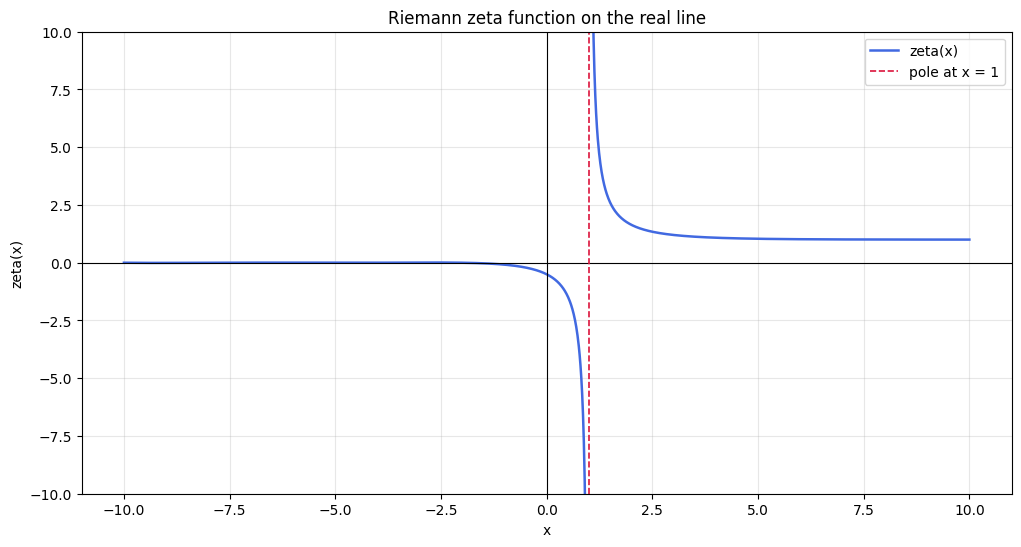

In [7]:
xs, ys = sample_zeta(-10, 10, step=0.01)

plt.figure(figsize=(12, 6))
plt.plot(xs, ys, color="royalblue", linewidth=1.8, label="zeta(x)")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(1, color="crimson", linestyle="--", linewidth=1.2, label="pole at x = 1")
plt.ylim(-10, 10)
plt.title("Riemann zeta function on the real line")
plt.xlabel("x")
plt.ylabel("zeta(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The large spike near `x = 1` is not a finite value. It is a vertical asymptote: `zeta(x)` goes to negative infinity from the left and positive infinity from the right.

For `x <= 1`, a few landmarks are worth noticing:

- `zeta(0) = -1/2`.
- The negative even integers are zeros: `zeta(-2) = zeta(-4) = zeta(-6) = ... = 0`.
- At negative odd integers the function alternates sign and grows in size.

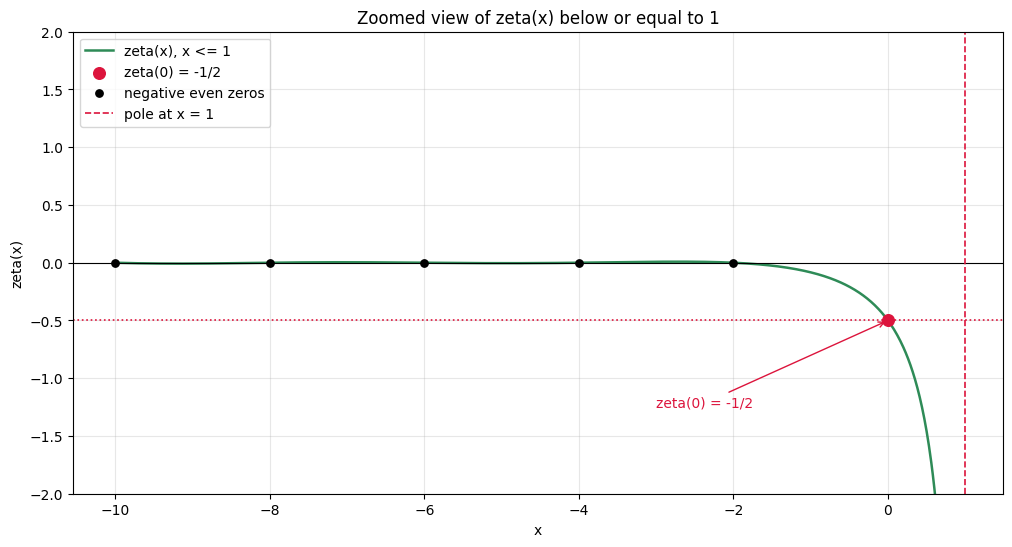

In [8]:
left_xs, left_ys = sample_zeta(-10, 1, step=0.01, gap_around_pole=0.06)

plt.figure(figsize=(12, 6))
plt.plot(left_xs, left_ys, color="seagreen", linewidth=1.8, label="zeta(x), x <= 1")
plt.scatter([0], [-0.5], color="crimson", s=70, zorder=4, label="zeta(0) = -1/2")
plt.scatter([-2, -4, -6, -8, -10], [0, 0, 0, 0, 0], color="black", s=28, zorder=3, label="negative even zeros")
plt.axhline(0, color="black", linewidth=0.8)
plt.axhline(-0.5, color="crimson", linestyle=":", linewidth=1.2)
plt.axvline(1, color="crimson", linestyle="--", linewidth=1.2, label="pole at x = 1")
plt.annotate("zeta(0) = -1/2", xy=(0, -0.5), xytext=(-3.0, -1.25), arrowprops={"arrowstyle": "->", "color": "crimson"}, color="crimson")
plt.ylim(-2, 2)
plt.title("Zoomed view of zeta(x) below or equal to 1")
plt.xlabel("x")
plt.ylabel("zeta(x)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [9]:
sample_points = [-10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 0.5, 0.9, 1.1, 2, 3, 4, 10]

for x in sample_points:
    print(f"zeta({x:>4}) = {zeta_real(x): .10g}")

zeta( -10) = -7.379210564e-18
zeta(  -9) = -0.007575757576
zeta(  -8) =  2.593426273e-18
zeta(  -7) =  0.004166666667
zeta(  -6) = -1.379896495e-18
zeta(  -5) = -0.003968253968
zeta(  -4) =  1.244890756e-18
zeta(  -3) =  0.008333333333
zeta(  -2) = -2.373866353e-18
zeta(  -1) = -0.08333333333
zeta(   0) = -0.5
zeta( 0.5) = -1.460354509
zeta( 0.9) = -9.430114019
zeta( 1.1) =  10.58444846
zeta(   2) =  1.644934067
zeta(   3) =  1.202056903
zeta(   4) =  1.082323234
zeta(  10) =  1.000994575
